In [2]:
import pandas as pd
import numpy as np
import re
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pandas.errors import SettingWithCopyWarning
from econml.dml import LinearDML
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MultiLabelBinarizer

warnings.simplefilter("ignore", SettingWithCopyWarning)

## Load Datasets


In [3]:
# BoardGameGeek dataset
bgg_dataset = pd.read_csv("bgg_dataset.csv", sep=';')
bgg_dataset.head(5)

,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,Owned Users,Mechanics,Domains
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,"8,79",1,"3,86",68323.0,"Action Queue, Action Retrieval, Campaign / Bat...","Strategy Games, Thematic Games"
1,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,"8,61",2,"2,84",65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games"
2,224517.0,Brass: Birmingham,2018.0,2,4,120,14,19217,"8,66",3,"3,91",28785.0,"Hand Management, Income, Loans, Market, Networ...",Strategy Games
3,167791.0,Terraforming Mars,2016.0,1,5,120,12,64864,"8,43",4,"3,24",87099.0,"Card Drafting, Drafting, End Game Bonuses, Han...",Strategy Games
4,233078.0,Twilight Imperium: Fourth Edition,2017.0,3,6,480,14,13468,"8,70",5,"4,22",16831.0,"Action Drafting, Area Majority / Influence, Ar...","Strategy Games, Thematic Games"


In [4]:
# Product/edition dataset
products_dataset = pd.read_csv('products_with_edition.csv')
products_dataset.head(5)

,productid,objecttype,objectid,producthref,price,currency,currencystring,currencysymbol,condition,prettycondition,...,quantity,userId,username,user_country,user_city,version_name,version_href,game_name,game_href,linkeduserGeekMarket
0,3870857,thing,1,/market/product/3870857,30.00,USD,U.S. dollars,$,likenew,Like New,...,1,2954044,LeBao,United States,Tallahassee,Die Macher (Multilingual edition 2006),/boardgameversion/24534/multilingual-edition-2006,Die Macher,/boardgame/1/die-macher,NaN
1,3866054,thing,1,/market/product/3866054,180.00,USD,U.S. dollars,$,new,New,...,1,3677448,CarsonChandler,United States,Christiansburg,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
2,3854476,thing,1,/market/product/3854476,41.99,USD,U.S. dollars,$,likenew,Like New,...,1,215794,Eric Engelmann,United States,Rockville,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
3,3853310,thing,1,/market/product/3853310,60.00,EUR,Euros,€,new,New,...,1,1613268,JillySilly,Belgium,NaN,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
4,3845442,thing,1,/market/product/3845442,50.00,USD,U.S. dollars,$,verygood,Very Good,...,1,38240,caesarmom,United States,Lorton,Die Macher (German-only second edition),/boardgameversion/24939/german-only-second-edi...,Die Macher,/boardgame/1/die-macher,NaN


## Currency conversion in product_dataset

In [5]:
def convert_to_usd(amount, currency, rates):
    currency = str(currency).upper()
    if currency not in rates or pd.isna(amount):
        return None
    return round(float(amount) * rates[currency], 2)

rates = {
    'USD': 1.0,
    'EUR': 1.10,
    'GBP': 1.30,
    'AUD': 0.65,
    'CAD': 0.75,
    'CHF': 1.05,
    'SGD': 0.73,
    'SEK': 0.10,
    'PLN': 0.24,
    'HUF': 0.0027,
    'MXN': 0.057,
    'NZD': 0.60,
    'JPY': 0.0073,
    'CNY': 0.14,
    'BRL': 0.19,
    'CZK': 0.042,
    'MYR': 0.21,
}

products_dataset['currency'] = products_dataset['currency'].str.upper()

products_dataset['price'] = products_dataset['price'] * products_dataset['currency'].map(rates)

products_dataset['currency'] = 'USD'

products_dataset['price'] = products_dataset['price'].round(2)
products_dataset.head(5)

,productid,objecttype,objectid,producthref,price,currency,currencystring,currencysymbol,condition,prettycondition,...,quantity,userId,username,user_country,user_city,version_name,version_href,game_name,game_href,linkeduserGeekMarket
0,3870857,thing,1,/market/product/3870857,30.00,USD,U.S. dollars,$,likenew,Like New,...,1,2954044,LeBao,United States,Tallahassee,Die Macher (Multilingual edition 2006),/boardgameversion/24534/multilingual-edition-2006,Die Macher,/boardgame/1/die-macher,NaN
1,3866054,thing,1,/market/product/3866054,180.00,USD,U.S. dollars,$,new,New,...,1,3677448,CarsonChandler,United States,Christiansburg,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
2,3854476,thing,1,/market/product/3854476,41.99,USD,U.S. dollars,$,likenew,Like New,...,1,215794,Eric Engelmann,United States,Rockville,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
3,3853310,thing,1,/market/product/3853310,66.00,USD,Euros,€,new,New,...,1,1613268,JillySilly,Belgium,NaN,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
4,3845442,thing,1,/market/product/3845442,50.00,USD,U.S. dollars,$,verygood,Very Good,...,1,38240,caesarmom,United States,Lorton,Die Macher (German-only second edition),/boardgameversion/24939/german-only-second-edi...,Die Macher,/boardgame/1/die-macher,NaN


## Clean Product Dataset

In [6]:
cols_to_keep = ["objectid", "price", "version_name", "condition"]
products_clean = products_dataset.loc[:, cols_to_keep].copy()

# Drop missing IDs/prices
products_clean = products_clean.dropna(subset=["objectid", "price"])

# Convert types
products_clean["objectid"] = pd.to_numeric(products_clean["objectid"], errors="coerce").astype('Int64')
products_clean["price"] = pd.to_numeric(products_clean["price"], errors="coerce")

# Standardize condition
products_clean["condition"] = products_clean["condition"].astype(str).str.lower().str.strip()

# Keep only 'new' condition
products_clean = products_clean[products_clean["condition"] == "new"]

# Clean version names
products_clean["version_name"] = products_clean["version_name"].astype(str).str.strip()

# Remove duplicates
products_clean = products_clean.drop_duplicates(subset=["objectid", "version_name", "condition", "price"])

# Average price for duplicate versions
products_clean_avg = products_clean.groupby(
    ["objectid", "version_name", "condition"], as_index=False
)["price"].mean()

# IQR-based outlier removal
Q1 = products_clean_avg["price"].quantile(0.25)
Q3 = products_clean_avg["price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

products_model_ready = products_clean_avg[
    (products_clean_avg["price"] >= lower_bound) & 
    (products_clean_avg["price"] <= upper_bound)
]

products_model_ready.head(5)

,objectid,version_name,condition,price
0,1,Die Macher (German-only second edition),new,73.63
1,1,Die Macher (Multilingual edition 2006),new,44.50
2,1,Die Macher (Spanish edition),new,46.20
3,1,Die Macher (Spielworxx English/German edition ...,new,71.50
8,5,Acquire (3M Bookshelf edition),new,64.50


## Clean BGG Dataset

In [7]:
# Numeric conversion
numeric_cols = ['Year Published', 'Rating Average', 'Complexity Average', 'BGG Rank']
int_cols = ['Min Players', 'Max Players', 'Play Time', 'Min Age', 'Users Rated', 'Owned Users']

for col in numeric_cols:
    bgg_dataset[col] = pd.to_numeric(bgg_dataset[col].astype(str).str.replace(',', '.'), errors='coerce')
for col in int_cols:
    bgg_dataset[col] = pd.to_numeric(bgg_dataset[col], errors='coerce')

# Strip text
for col in ['Name', 'Mechanics', 'Domains']:
    bgg_dataset[col] = bgg_dataset[col].astype(str).str.strip()

# Drop rows with missing values
bgg_cleaned = bgg_dataset.dropna().copy()

bgg_cleaned.head(5)

,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,Owned Users,Mechanics,Domains
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,3.86,68323.0,"Action Queue, Action Retrieval, Campaign / Bat...","Strategy Games, Thematic Games"
1,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,2.84,65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games"
2,224517.0,Brass: Birmingham,2018.0,2,4,120,14,19217,8.66,3,3.91,28785.0,"Hand Management, Income, Loans, Market, Networ...",Strategy Games
3,167791.0,Terraforming Mars,2016.0,1,5,120,12,64864,8.43,4,3.24,87099.0,"Card Drafting, Drafting, End Game Bonuses, Han...",Strategy Games
4,233078.0,Twilight Imperium: Fourth Edition,2017.0,3,6,480,14,13468,8.70,5,4.22,16831.0,"Action Drafting, Area Majority / Influence, Ar...","Strategy Games, Thematic Games"


## Merge Product and BGG datasets

In [8]:
bgg_cleaned['ID'] = pd.to_numeric(bgg_cleaned['ID'], errors='coerce')
products_model_ready['objectid'] = pd.to_numeric(products_model_ready['objectid'], errors='coerce')

# Filter products in BGG
products_model_ready = products_model_ready[products_model_ready['objectid'].isin(bgg_cleaned['ID'])]

# Aggregate by version
products_grouped = products_model_ready.groupby(['objectid', 'version_name'], as_index=False).agg({
    'price': 'mean',
    'condition': 'first'
})

# Merge
bgg_merged = bgg_cleaned.merge(
    products_grouped[['objectid', 'price', 'condition', 'version_name']],
    how='left', left_on='ID', right_on='objectid'
)
bgg_merged.drop(columns=['objectid'], inplace=True)

# Clean unrealistic values
bgg_merged = bgg_merged[
    (bgg_merged['Year Published'] >= 1900) &
    (bgg_merged['Min Players'] > 0) &
    (bgg_merged['Max Players'] <= 20) &
    (bgg_merged['Play Time'] <= 600) &
    (bgg_merged['Min Age'] >= 0) &
    ((bgg_merged['price'].isna()) | (bgg_merged['price'] <= 300))
]

bgg_final = bgg_merged.dropna(subset=['price', 'version_name', 'condition'])
bgg_final.rename(columns={'BGG Rank': 'Success Rank'}, inplace=True)

bgg_final.head(5)

,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,Success Rank,Complexity Average,Owned Users,Mechanics,Domains,price,condition,version_name
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,3.86,68323.0,"Action Queue, Action Retrieval, Campaign / Bat...","Strategy Games, Thematic Games",98.450000,new,"Gloomhaven (German edition, first printing)"
1,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,2.84,65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games",63.810000,new,Pandemic Legacy: Season 1 (English blue editio...
2,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,2.84,65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games",81.730000,new,Pandemic Legacy: Season 1 (English blue editio...
3,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,2.84,65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games",61.666667,new,Pandemic Legacy: Season 1 (English red edition...
4,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,2.84,65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games",77.833333,new,Pandemic Legacy: Season 1 (English red edition...


## Data Preprocessing and Labeling

In [9]:
# Complexity label
bgg_final["complexity_label"] = pd.cut(
    bgg_final["Complexity Average"], bins=[0, 2, 3.5, 5],
    labels=["Easy", "Medium", "Hard"], include_lowest=True
)

# High rating flag
bgg_final["highly_rated"] = bgg_final["Rating Average"] >= 8

# Game type classification
def classify_game_type(domains):
    if pd.isna(domains):
        return "Unknown"
    d = domains.lower()
    strategy_keywords = ["strategy", "abstract", "war", "wargame", "economic"]
    thematic_keywords = ["thematic", "adventure", "fantasy", "horror", "science fiction", "story", "exploration"]
    family_keywords = ["family", "children", "party", "puzzle", "dexterity", "trivia"]
    is_strategy = any(k in d for k in strategy_keywords)
    is_thematic = any(k in d for k in thematic_keywords)
    is_family = any(k in d for k in family_keywords)
    if is_strategy and is_thematic: return "Hybrid"
    elif is_strategy: return "Strategy"
    elif is_thematic: return "Thematic"
    elif is_family: return "Family/Party"
    else: return "Other"

bgg_final["game_type"] = bgg_final["Domains"].apply(classify_game_type)

# Price category
bgg_final["price_category"] = pd.cut(
    bgg_final["price"], bins=[0, 20, 50, 100, 500, 1000],
    labels=["very low", "low", "medium", "high", "very high"]
)

# Value-for-money features
bgg_final["rating_per_dollar"] = bgg_final["Rating Average"] / bgg_final["price"]
bgg_final["complexity_per_dollar"] = bgg_final["Complexity Average"] / bgg_final["price"]

# Mechanic annotation
mechanic_map = {
    "dice-driven": ["dice", "roll", "yahtzee"],
    "worker-placement": ["worker placement", "placement"],
    "deck-building": ["deck building", "deckbuilding"],
    "drafting": ["draft", "card drafting"],
    "tile-placement": ["tile placement", "domino", "polyomino"],
    "area-control": ["area control", "area majority"],
    "resource-management": ["resource", "economy", "produce"],
    "engine-building": ["engine", "combo", "synergy"],
    "set-collection": ["set collection"],
    "hand-management": ["hand management"],
    "card-based": ["card", "deck", "hand"],
    "co-op": ["cooperative", "co-op", "team"],
    "campaign-legacy": ["legacy", "campaign", "scenario"],
    "hidden-information": ["hidden", "secret", "deduction"],
    "bluffing": ["bluff", "traitor"],
    "puzzle": ["puzzle", "logic"],
    "party": ["party", "social"],
    "conflict-combat": ["combat", "fight", "battle"],
    "trading-negotiation": ["trade", "negotiation"]
}

def annotate_mechanics(text):
    if pd.isna(text):
        return ["other"]
    parts = [p.strip().lower() for p in text.split(",")]
    matched = set()
    for part in parts:
        for label, keywords in mechanic_map.items():
            if any(kw in part for kw in keywords):
                matched.add(label)
    return list(matched) if matched else ["other"]

bgg_final["Mechanics_annotated"] = bgg_final["Mechanics"].apply(annotate_mechanics)

# Explode for analysis
bgg_exploded = bgg_final.explode("Mechanics_annotated")

bgg_model_ready = bgg_final.drop(
    columns=["Name", "Mechanics", "Domains"]
)



In [10]:
bgg_model_ready.head(5)


,ID,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,Success Rank,Complexity Average,...,price,condition,version_name,complexity_label,highly_rated,game_type,price_category,rating_per_dollar,complexity_per_dollar,Mechanics_annotated
0,174430.0,2017.0,1,4,120,14,42055,8.79,1,3.86,...,98.450000,new,"Gloomhaven (German edition, first printing)",Hard,True,Hybrid,medium,0.089284,0.039208,"[hand-management, card-based, campaign-legacy,..."
1,161936.0,2015.0,2,4,60,13,41643,8.61,2,2.84,...,63.810000,new,Pandemic Legacy: Season 1 (English blue editio...,Medium,True,Hybrid,medium,0.134932,0.044507,"[hand-management, card-based, campaign-legacy,..."
2,161936.0,2015.0,2,4,60,13,41643,8.61,2,2.84,...,81.730000,new,Pandemic Legacy: Season 1 (English blue editio...,Medium,True,Hybrid,medium,0.105347,0.034749,"[hand-management, card-based, campaign-legacy,..."
3,161936.0,2015.0,2,4,60,13,41643,8.61,2,2.84,...,61.666667,new,Pandemic Legacy: Season 1 (English red edition...,Medium,True,Hybrid,medium,0.139622,0.046054,"[hand-management, card-based, campaign-legacy,..."
4,161936.0,2015.0,2,4,60,13,41643,8.61,2,2.84,...,77.833333,new,Pandemic Legacy: Season 1 (English red edition...,Medium,True,Hybrid,medium,0.110621,0.036488,"[hand-management, card-based, campaign-legacy,..."


In [11]:
bgg_exploded.head(5)


,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,Success Rank,...,price,condition,version_name,complexity_label,highly_rated,game_type,price_category,rating_per_dollar,complexity_per_dollar,Mechanics_annotated
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,...,98.45,new,"Gloomhaven (German edition, first printing)",Hard,True,Hybrid,medium,0.089284,0.039208,hand-management
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,...,98.45,new,"Gloomhaven (German edition, first printing)",Hard,True,Hybrid,medium,0.089284,0.039208,card-based
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,...,98.45,new,"Gloomhaven (German edition, first printing)",Hard,True,Hybrid,medium,0.089284,0.039208,campaign-legacy
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,...,98.45,new,"Gloomhaven (German edition, first printing)",Hard,True,Hybrid,medium,0.089284,0.039208,co-op
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,...,98.45,new,"Gloomhaven (German edition, first printing)",Hard,True,Hybrid,medium,0.089284,0.039208,conflict-combat


In [12]:
bgg_final.head(5)

,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,Success Rank,...,price,condition,version_name,complexity_label,highly_rated,game_type,price_category,rating_per_dollar,complexity_per_dollar,Mechanics_annotated
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,...,98.450000,new,"Gloomhaven (German edition, first printing)",Hard,True,Hybrid,medium,0.089284,0.039208,"[hand-management, card-based, campaign-legacy,..."
1,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,...,63.810000,new,Pandemic Legacy: Season 1 (English blue editio...,Medium,True,Hybrid,medium,0.134932,0.044507,"[hand-management, card-based, campaign-legacy,..."
2,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,...,81.730000,new,Pandemic Legacy: Season 1 (English blue editio...,Medium,True,Hybrid,medium,0.105347,0.034749,"[hand-management, card-based, campaign-legacy,..."
3,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,...,61.666667,new,Pandemic Legacy: Season 1 (English red edition...,Medium,True,Hybrid,medium,0.139622,0.046054,"[hand-management, card-based, campaign-legacy,..."
4,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,...,77.833333,new,Pandemic Legacy: Season 1 (English red edition...,Medium,True,Hybrid,medium,0.110621,0.036488,"[hand-management, card-based, campaign-legacy,..."


## Final datasets

In [13]:
bgg_final.to_csv("bgg_final.csv", index=False)
bgg_model_ready.to_csv("bgg_model_ready.csv", index=False)
bgg_exploded.to_csv("bgg_mechanics_exploded.csv", index=False)

print("All datasets saved successfully")
print("Model-ready dataset shape:", bgg_model_ready.shape)
print("Final BGG dataset shape:", bgg_final.shape)
print("Exploded mechanics dataset shape:", bgg_exploded.shape)

All datasets saved successfully
Model-ready dataset shape: (22826, 21)
Final BGG dataset shape: (22826, 24)
Exploded mechanics dataset shape: (49098, 24)


## Exploratory Data Analysis

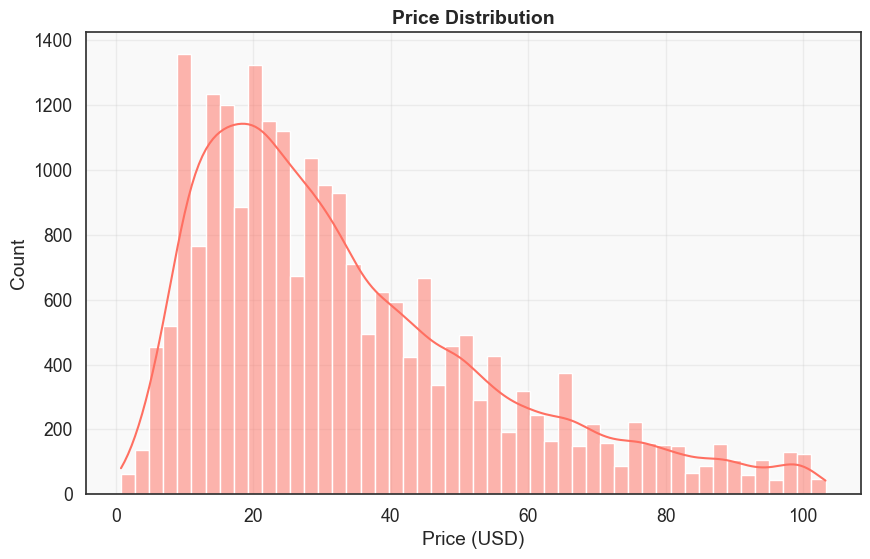

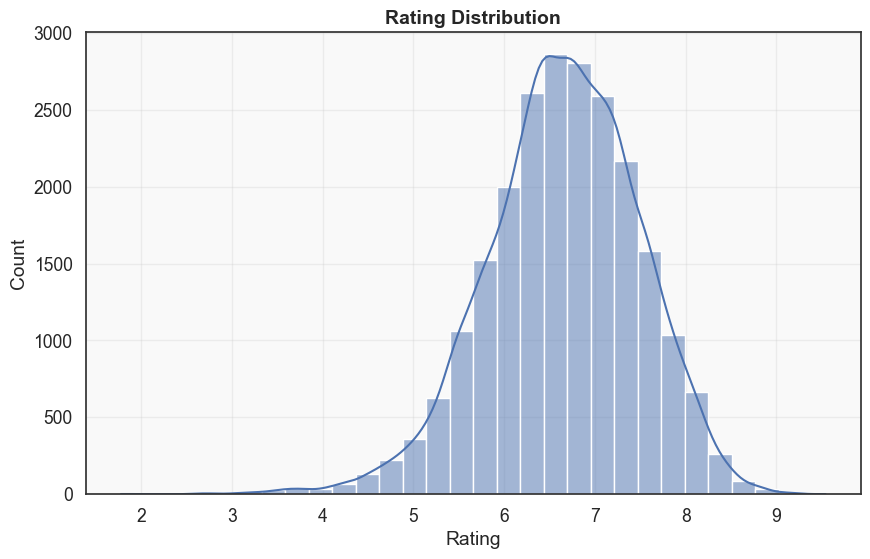

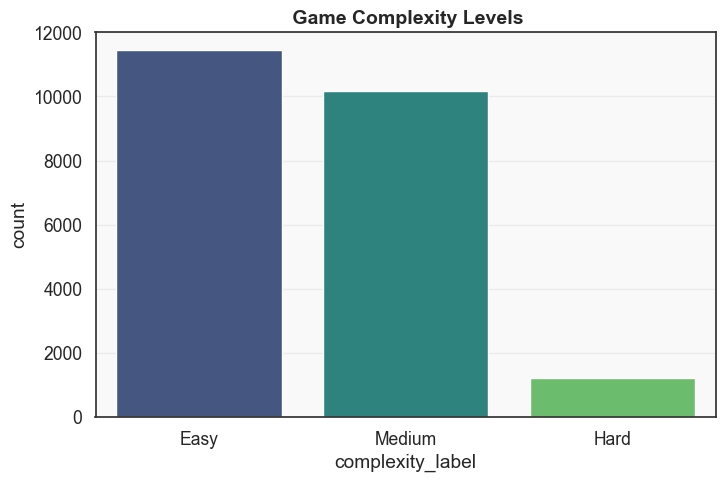

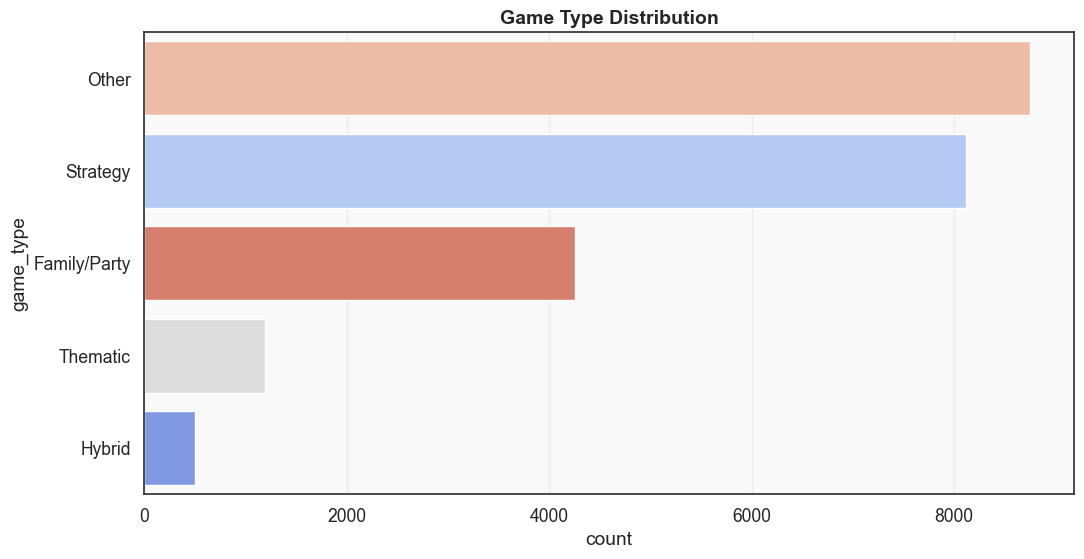

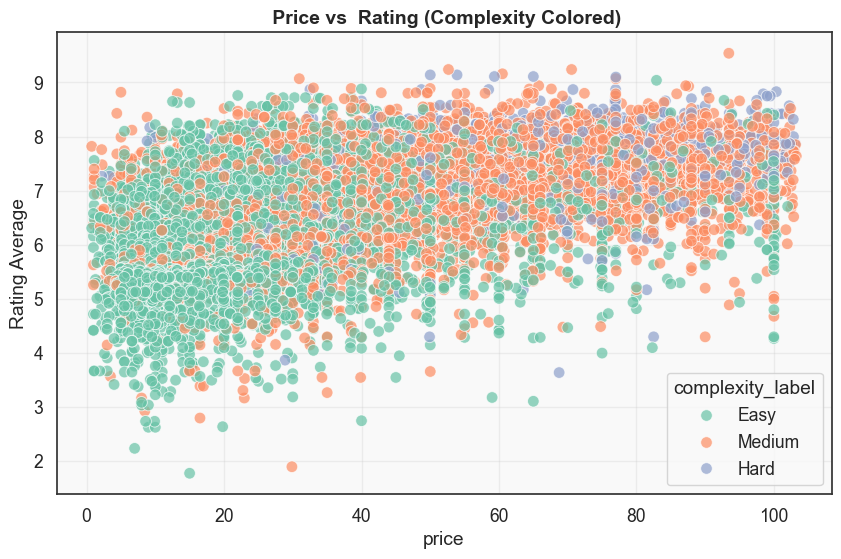

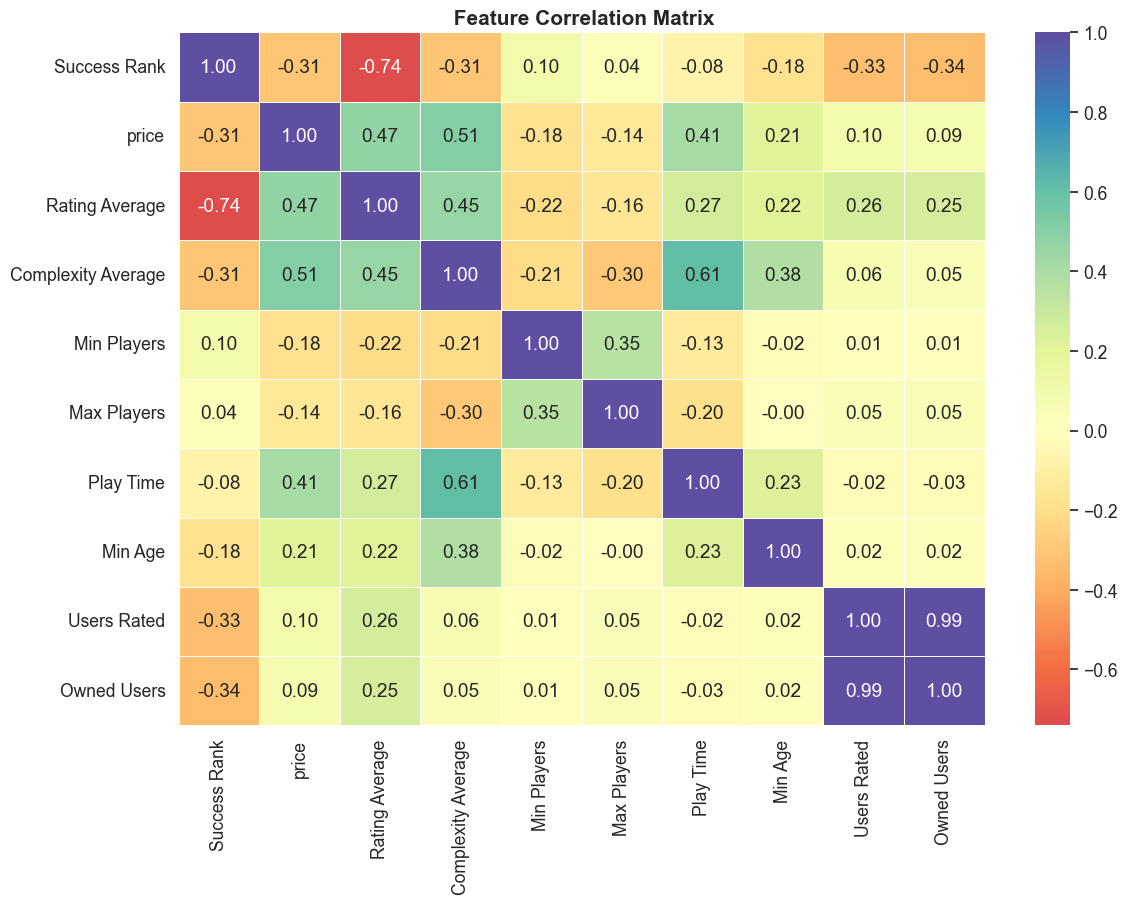

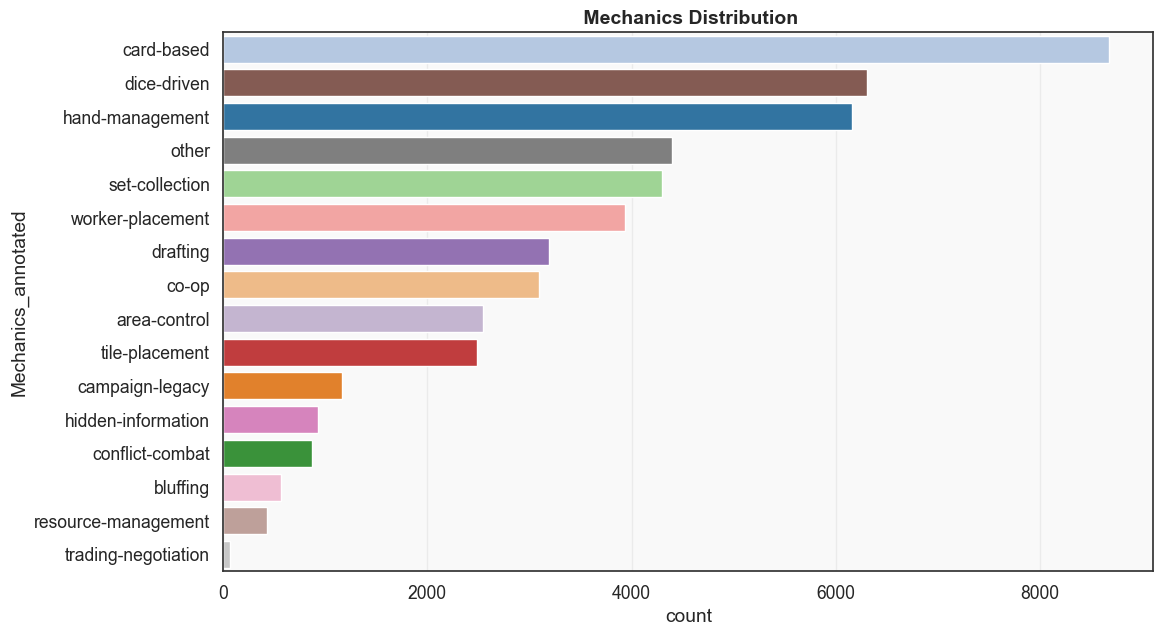

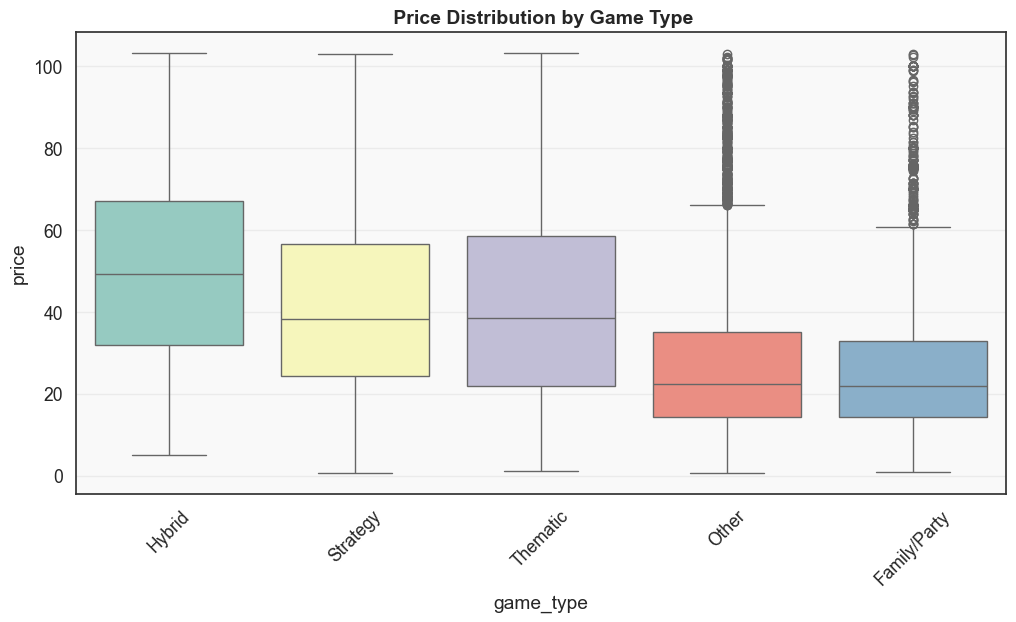

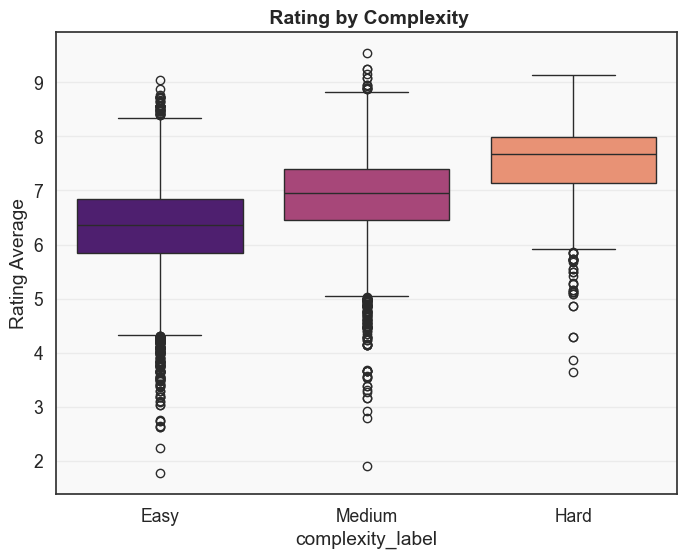

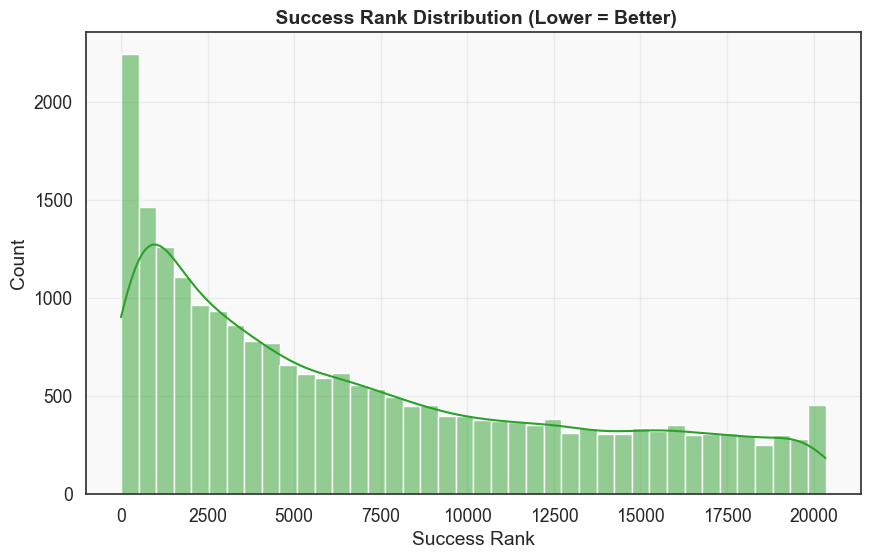

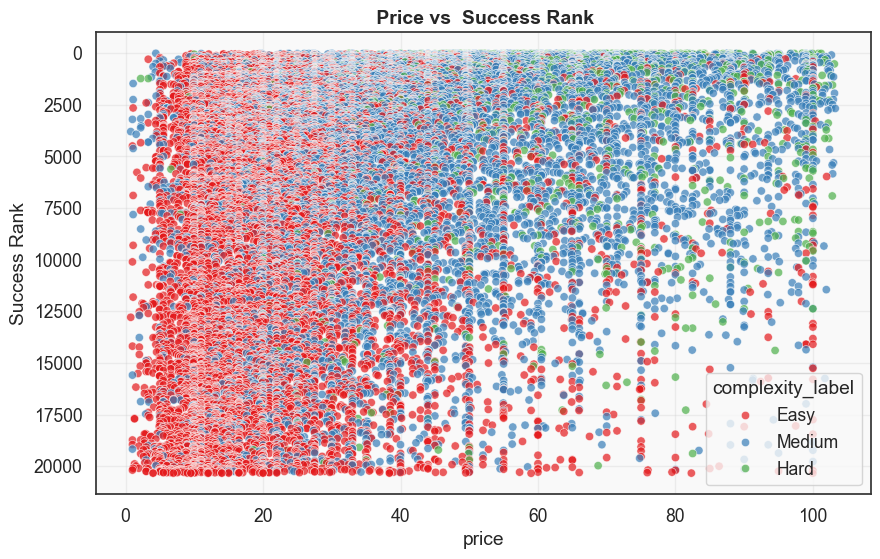

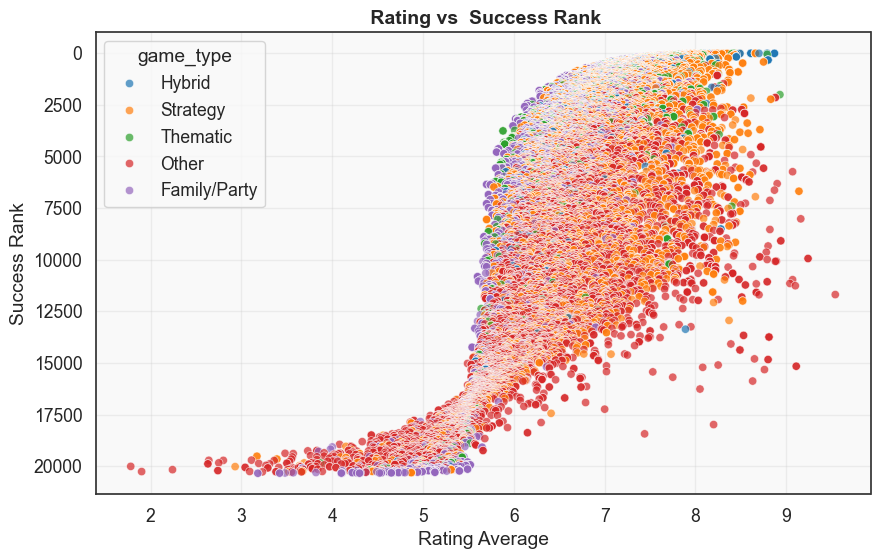

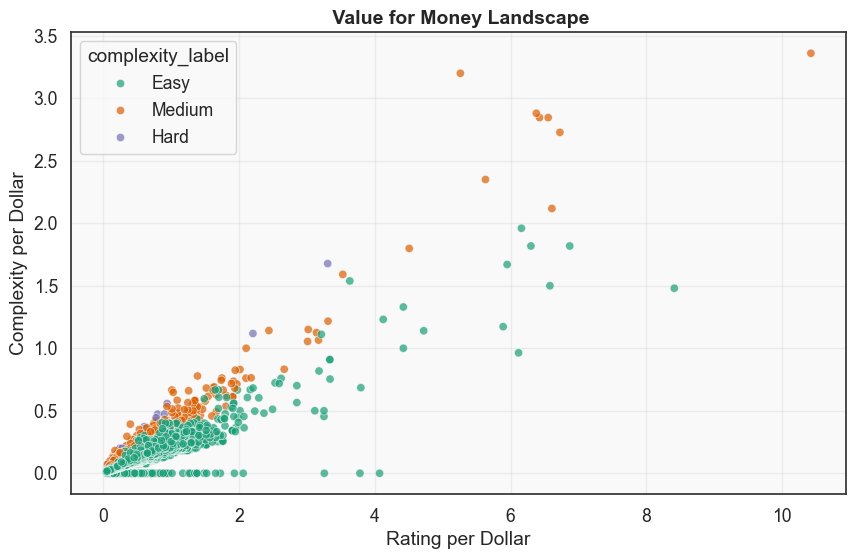

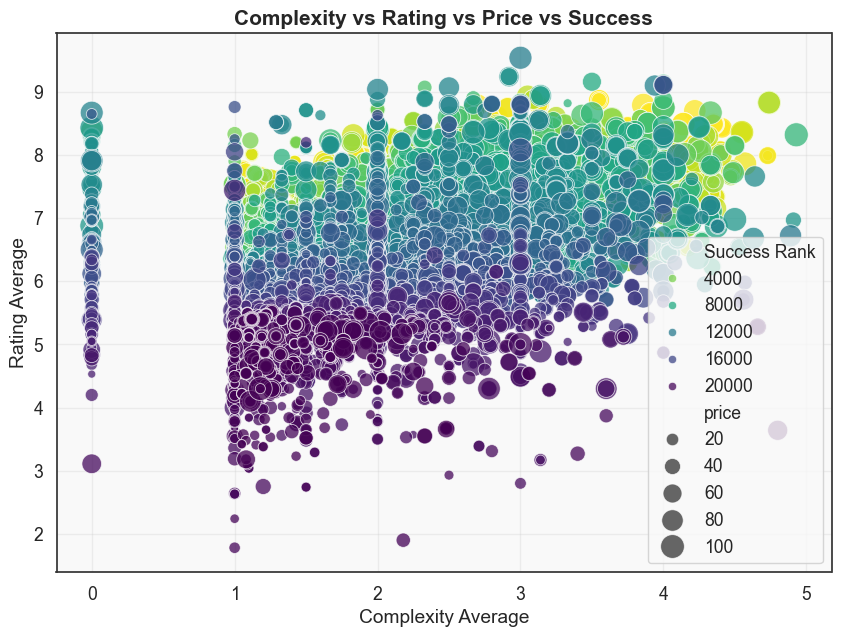

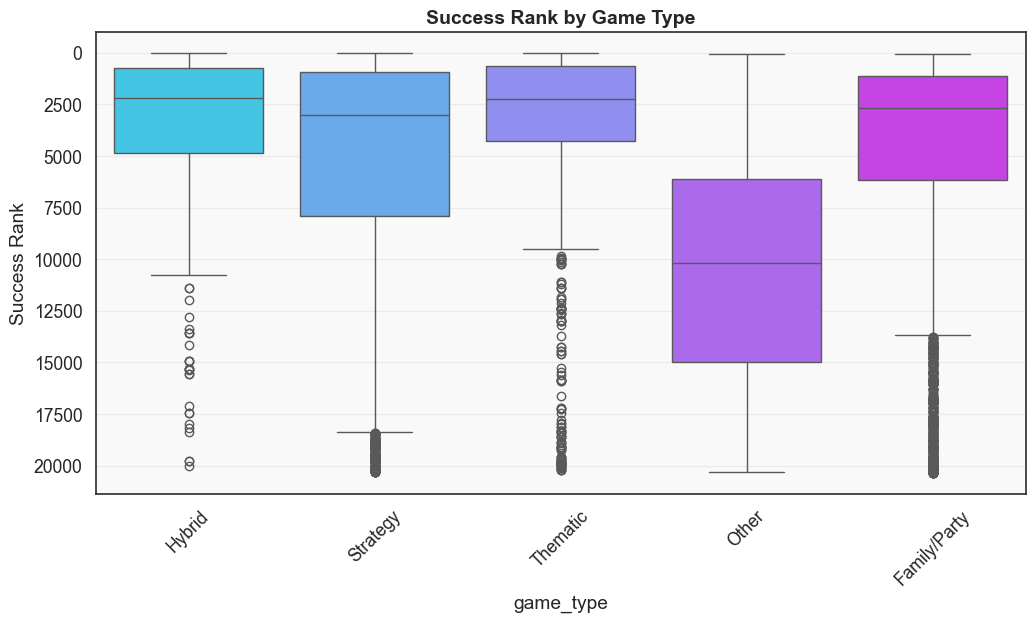

In [22]:
sns.set_theme(
    style="whitegrid",
    palette="Spectral",
    font_scale=1.15,
    rc={
        "axes.facecolor": "#f9f9f9",
        "grid.alpha": 0.3,
        "axes.edgecolor": "0.2",
        "figure.facecolor": "white"
    }
)


# PRICE DISTRIBUTION

plt.figure(figsize=(10,6))
sns.histplot(bgg_final['price'], bins=50, kde=True, color="#ff6f61")
plt.title("Price Distribution", fontsize=14, weight="bold")
plt.xlabel("Price (USD)")
plt.ylabel("Count")
plt.show()


#  RATING DISTRIBUTION

plt.figure(figsize=(10,6))
sns.histplot(bgg_final['Rating Average'], bins=30, kde=True, color="#4c72b0")
plt.title("Rating Distribution", fontsize=14, weight="bold")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()


# COMPLEXITY LABEL

plt.figure(figsize=(8,5))
sns.countplot(
    x="complexity_label",
    hue="complexity_label",
    data=bgg_final,
    order=["Easy","Medium","Hard"],
    palette="viridis",
    legend=False
)
plt.title(" Game Complexity Levels", fontsize=14, weight="bold")
plt.show()


#  GAME TYPE DISTRIBUTION

plt.figure(figsize=(12,6))
sns.countplot(
    y="game_type",
    hue="game_type",
    data=bgg_final,
    order=bgg_final["game_type"].value_counts().index,
    palette="coolwarm",
    legend=False
)
plt.title("Game Type Distribution", fontsize=14, weight="bold")
plt.show()


#  PRICE vs RATING

plt.figure(figsize=(10,6))
sns.scatterplot(
    x="price",
    y="Rating Average",
    hue="complexity_label",
    palette="Set2",
    data=bgg_final,
    alpha=0.7,
    s=70
)
plt.title(" Price vs  Rating (Complexity Colored)", fontsize=14, weight="bold")
plt.show()

 
# CORRELATION HEATMAP

numeric_cols = [
    "Success Rank","price", "Rating Average", "Complexity Average", 
    "Min Players", "Max Players", "Play Time", 
    "Min Age", "Users Rated", "Owned Users"
]

plt.figure(figsize=(13,9))
sns.heatmap(
    bgg_final[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="Spectral",
    center=0,
    linewidths=0.6
)
plt.title(" Feature Correlation Matrix", fontsize=15, weight="bold")
plt.show()


#  MECHANICS DISTRIBUTION

plt.figure(figsize=(12,7))
sns.countplot(
    y="Mechanics_annotated",
    hue="Mechanics_annotated",
    data=bgg_exploded,
    order=bgg_exploded["Mechanics_annotated"].value_counts().index,
    palette="tab20",
    legend=False
)
plt.title(" Mechanics Distribution", fontsize=14, weight="bold")
plt.show()


#  PRICE BY GAME TYPE

plt.figure(figsize=(12,6))
sns.boxplot(
    x="game_type",
    y="price",
    hue="game_type",
    data=bgg_final,
    palette="Set3",
    legend=False
)
plt.xticks(rotation=45)
plt.title(" Price Distribution by Game Type", fontsize=14, weight="bold")
plt.show()


#  RATING BY COMPLEXITY

plt.figure(figsize=(8,6))
sns.boxplot(
    x="complexity_label",
    y="Rating Average",
    hue="complexity_label",
    data=bgg_final,
    order=["Easy","Medium","Hard"],
    palette="magma",
    legend=False
)
plt.title(" Rating by Complexity", fontsize=14, weight="bold")
plt.show()


#  SUCCESS RANK DISTRIBUTION

plt.figure(figsize=(10,6))
sns.histplot(bgg_final["Success Rank"], bins=40, kde=True, color="#2ca02c")
plt.title(" Success Rank Distribution (Lower = Better)", fontsize=14, weight="bold")
plt.xlabel("Success Rank")
plt.show()


#  PRICE vs SUCCESS RANK

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=bgg_final,
    x="price",
    y="Success Rank",
    hue="complexity_label",
    palette="Set1",
    alpha=0.7
)
plt.gca().invert_yaxis()
plt.title(" Price vs  Success Rank", fontsize=14, weight="bold")
plt.show()


#  RATING vs SUCCESS RANK

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=bgg_final,
    x="Rating Average",
    y="Success Rank",
    hue="game_type",
    palette="tab10",
    alpha=0.7
)
plt.gca().invert_yaxis()
plt.title(" Rating vs  Success Rank", fontsize=14, weight="bold")
plt.show()


# VALUE FOR MONEY

plt.figure(figsize=(10,6))
sns.scatterplot(
    x="rating_per_dollar",
    y="complexity_per_dollar",
    hue="complexity_label",
    palette="Dark2",
    data=bgg_final,
    alpha=0.7
)
plt.title(" Value for Money Landscape", fontsize=14, weight="bold")
plt.xlabel("Rating per Dollar")
plt.ylabel("Complexity per Dollar")
plt.show()


# ULTIMATE BUBBLE CHART

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=bgg_final,
    x="Complexity Average",
    y="Rating Average",
    size="price",
    hue="Success Rank",
    palette="viridis_r",
    sizes=(30, 300),
    alpha=0.75
)
plt.title("Complexity vs Rating vs Price vs Success", fontsize=15, weight="bold")
plt.show()


#  SUCCESS BY GAME TYPE

plt.figure(figsize=(12,6))
sns.boxplot(
    data=bgg_final,
    x="game_type",
    y="Success Rank",
    hue="game_type",
    palette="cool",
    legend=False
)
plt.gca().invert_yaxis()
plt.xticks(rotation=45)
plt.title("Success Rank by Game Type", fontsize=14, weight="bold")
plt.show()


## Mechanics Associated with More Successful Games

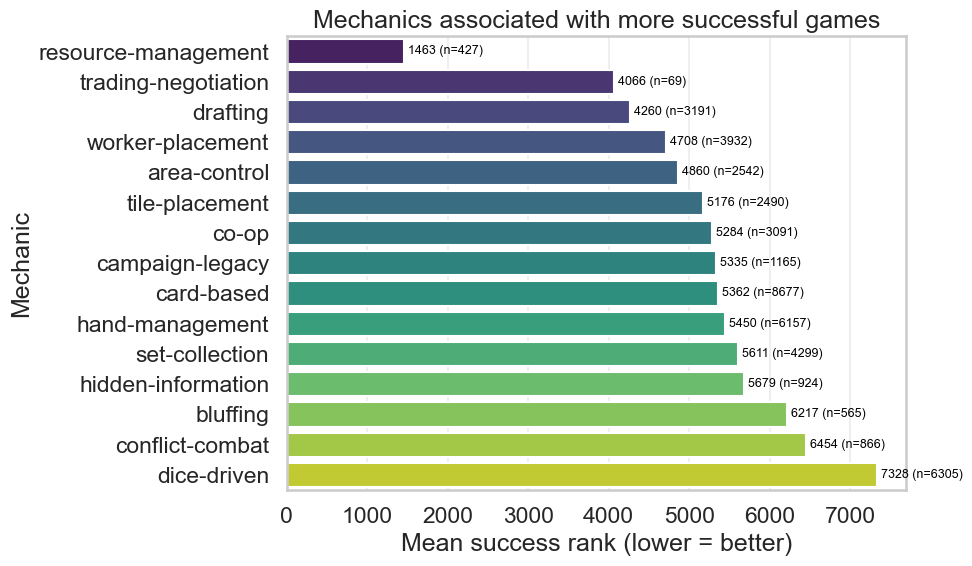

In [15]:
mech_exploded = (
    bgg_final
    # just fill NaN lists with empty lists; no split
    .assign(Mechanics_annotated=bgg_final['Mechanics_annotated'].apply(
        lambda x: x if isinstance(x, list) else []
    ))
    .explode('Mechanics_annotated')
)

# now Mechanics_annotated contains single mechanic strings
mech_exploded['Mechanics_annotated'] = mech_exploded['Mechanics_annotated'].astype(str).str.strip()
mech_exploded = mech_exploded[mech_exploded['Mechanics_annotated'] != ""]

mech_summary = (
    mech_exploded
    .groupby('Mechanics_annotated', as_index=False)
    .agg(mean_rank=('Success Rank', 'mean'),
         count=('Success Rank', 'size'))
    .dropna(subset=['mean_rank'])
    .sort_values('mean_rank')
)

mech_summary.head(15)

# Visualize
import seaborn as sns
import matplotlib.pyplot as plt

# pick mechanics with enough games and best average rank
plot_df = mech_summary.query('count >= 50').nsmallest(15, 'mean_rank')

sns.set_style("whitegrid")
sns.set_context("talk")  # slightly larger fonts

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=plot_df,
    y='Mechanics_annotated',
    x='mean_rank',
    hue='Mechanics_annotated',
    palette='viridis',
    legend=False
)

plt.xlabel('Mean success rank (lower = better)')
plt.ylabel('Mechanic')
plt.title('Mechanics associated with more successful games')

# add value labels: mean rank and count
for i, row in plot_df.iterrows():
    ax.text(
        row['mean_rank'] + 50,  # a bit to the right of the bar
        ax.get_yticks()[list(plot_df.index).index(i)],
        f"{row['mean_rank']:.0f} (n={row['count']})",
        va='center',
        fontsize=9,
        color='black'
    )

plt.tight_layout()
plt.show()


## Single Linear Regressions (One predictor at a time)

In [16]:
# ===============================
# 1. PREPARE DATA FOR OLS MODELS
# ===============================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------
# Transform the target
# -----------------------
# Succcess Rank: 1 = best, large numbers = worst
# Convert to a success score: 0 (worst) → 1 (best)
max_rank = bgg_final['Success Rank'].max()
bgg_final['SuccessScore'] = (max_rank - bgg_final['Success Rank'] + 1) / max_rank

# -----------------------
# Log-transform skewed predictors
# -----------------------
skewed_cols = ['Owned Users', 'Users Rated', 'price']
for col in skewed_cols:
    bgg_final['log_' + col] = np.log1p(bgg_final[col])

# -----------------------
# Select predictors
# -----------------------
predictors = [
    'log_Users Rated',
    'log_Owned Users',
    'Rating Average',
    'Year Published',
    'Min Players',
    'Max Players',
    'Play Time',
    'Complexity Average',
    'log_price'
]


===== Single OLS: log_Users Rated =====
R-squared: 0.565409136921408
                     coef        pvalue
const           -0.083145  2.139512e-83
log_Users Rated  0.119108  0.000000e+00


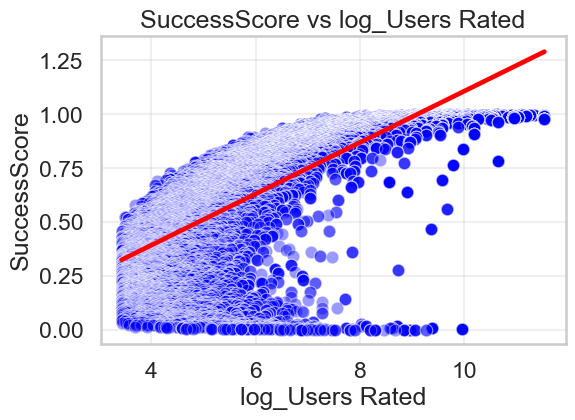


===== Single OLS: log_Owned Users =====
R-squared: 0.5384313885696266
                     coef  pvalue
const           -0.255733     0.0
log_Owned Users  0.130446     0.0


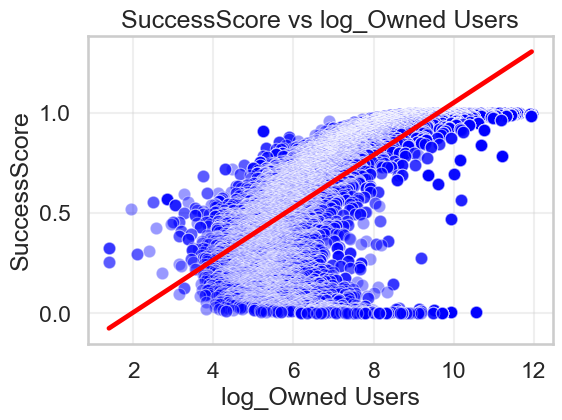


===== Single OLS: Rating Average =====
R-squared: 0.5483092059590118
                    coef  pvalue
const          -1.073797     0.0
Rating Average  0.259755     0.0


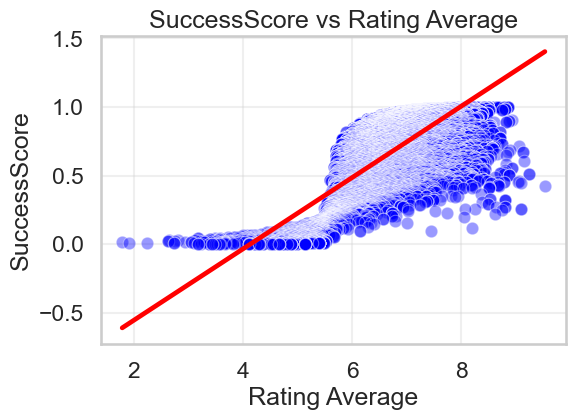


===== Single OLS: Year Published =====
R-squared: 0.05133168238828045
                     coef         pvalue
const          -11.466304  5.053146e-191
Year Published   0.006031  1.517243e-213


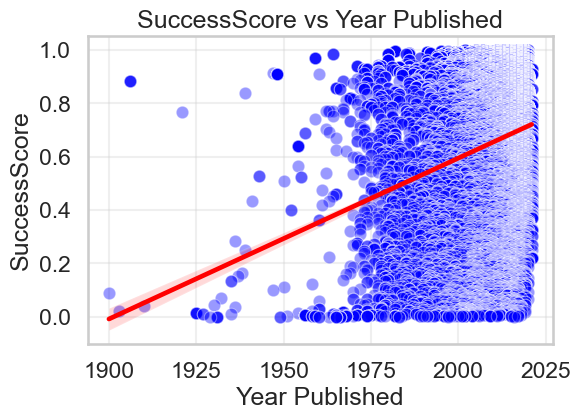


===== Single OLS: Min Players =====
R-squared: 0.00995655394618733
                 coef        pvalue
const        0.740305  0.000000e+00
Min Players -0.043369  1.717891e-49


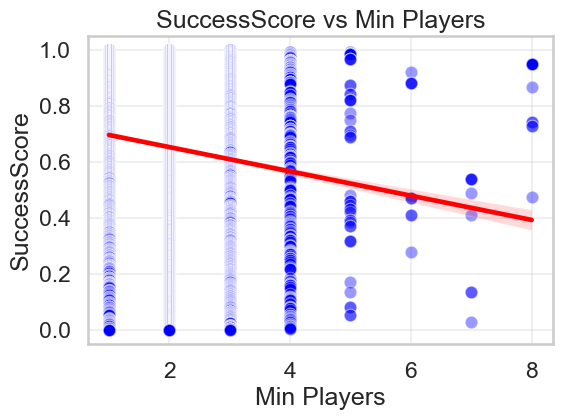


===== Single OLS: Max Players =====
R-squared: 0.001458760768466627
                 coef        pvalue
const        0.677755  0.000000e+00
Max Players -0.005150  6.970036e-08


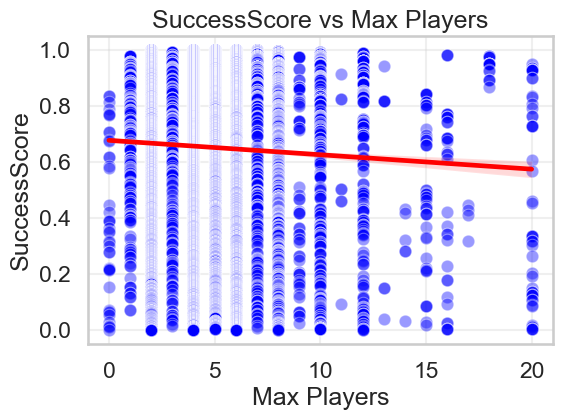


===== Single OLS: Play Time =====
R-squared: 0.006201452843970445
               coef        pvalue
const      0.631091  0.000000e+00
Play Time  0.000309  9.683884e-37


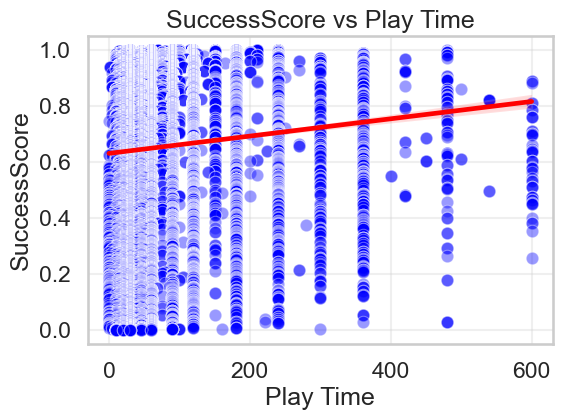


===== Single OLS: Complexity Average =====
R-squared: 0.09452384691435278
                        coef  pvalue
const               0.416043     0.0
Complexity Average  0.112474     0.0


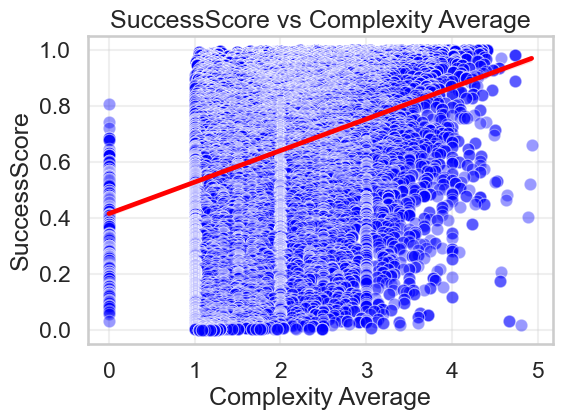


===== Single OLS: log_price =====
R-squared: 0.11803815343559265
               coef        pvalue
const      0.138050  3.025075e-44
log_price  0.153864  0.000000e+00


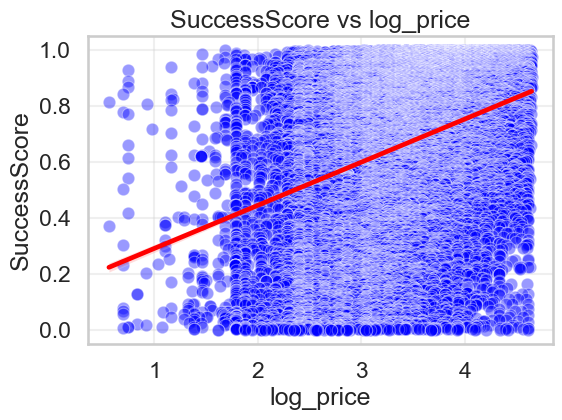

In [21]:
# ===============================
# 2. SINGLE LINEAR REGRESSIONS
# ===============================

def single_ols(feature):
    X = sm.add_constant(bgg_final[[feature]])
    y = bgg_final['SuccessScore']

    model = sm.OLS(y, X).fit(cov_type='HC3')  # robust standard errors
    print(f"\n===== Single OLS: {feature} =====")
    # display(model.summary())
    results = model
    print("R-squared:", results.rsquared)
    rel = pd.DataFrame({
    "coef": results.params,
    "pvalue": results.pvalues})
    print(rel)


    # Plot regression line
    plt.figure(figsize=(6,4))
    sns.scatterplot(x=bgg_final[feature], y=y, alpha=0.4, color='blue')
    sns.regplot(x=bgg_final[feature], y=y, scatter=False, color='red')
    plt.title(f"SuccessScore vs {feature}")
    plt.show()


for f in predictors:
    single_ols(f)

## Multiple Linear Regression using top 3 predictors

In [17]:
# ============================================
# 3. Extracting top 3 predictors by coefficient
# ============================================

coef_list = []

for feature in predictors:
    X = sm.add_constant(bgg_final[[feature]])
    y = bgg_final['SuccessScore']
    
    model = sm.OLS(y, X).fit(cov_type='HC3')
    
    coef = model.params[feature]
    
    coef_list.append({
        "predictor": feature,
        "coef": coef,
        "abs_coef": abs(coef)
    })

coef_df = pd.DataFrame(coef_list)
display(coef_df)

# ---- Select top 3 by absolute coefficient ----
top3 = coef_df.sort_values("abs_coef", ascending=False).head(3)
top3_predictors = top3["predictor"].tolist()

print("\nTop 3 predictors:", top3_predictors)

,predictor,coef,abs_coef
0,log_Users Rated,0.119108,0.119108
1,log_Owned Users,0.130446,0.130446
2,Rating Average,0.259755,0.259755
3,Year Published,0.006031,0.006031
4,Min Players,-0.043369,0.043369
5,Max Players,-0.005150,0.005150
6,Play Time,0.000309,0.000309
7,Complexity Average,0.112474,0.112474
8,log_price,0.153864,0.153864



Top 3 predictors: ['Rating Average', 'log_price', 'log_Owned Users']


In [18]:
# ============================================
# 4. Multiple regression using top 3 predictors
# ============================================
X = sm.add_constant(bgg_final[top3_predictors])
y = bgg_final['SuccessScore']

multi_model = sm.OLS(y, X).fit(cov_type='HC3')
print("\n===== Multiple Linear Regression (Top 3 Predictors) =====")
# display(multi_model.summary())
# Print coefficients only (including constant)
print("\nCoefficients:")
print(multi_model.params)

# Print R-squared only
print("\nR-squared:", multi_model.rsquared)


===== Multiple Linear Regression (Top 3 Predictors) =====

Coefficients:
const             -1.246345
Rating Average     0.192945
log_price         -0.010967
log_Owned Users    0.093753
dtype: float64

R-squared: 0.7858434005119377


## Interpretation of regression coefficients

Rating Average coefficient ≈ 0.19 If rating increases by 1 point (holding price and Owned Users constant), SuccessScore increases by about 0.19, meaning higher ratings strongly improve success.

log_Owned Users coefficient ≈ 0.094 If the number of owners increases (holding rating and price constant), SuccessScore increases by about 0.09, so popular games tend to be more successful.

log_price coefficient ≈ –0.011 If price increases (holding rating and Owned Users constant), SuccessScore decreases slightly by about 0.01, meaning higher price has a small negative effect on success

So it shows Rating Average is more important than price or others predictors for success of a board game

## Casual Inference: Success Rank

In [19]:
# 1 Numeric confounders and treatments

numeric_cols = bgg_model_ready.select_dtypes(include=np.number).columns.tolist()
numeric_treatments = ['Rating Average', 'Complexity Average', 'price', 'Year Published', 'Min Players']
outcome = 'Success Rank'
numeric_confounders = list(set(numeric_cols) - set(numeric_treatments) - {outcome})

X_num = bgg_model_ready[numeric_confounders]

# Scale numeric confounders
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

# Convert scaled numeric features to DataFrame to align indices safely
X_num_scaled_df = pd.DataFrame(X_num_scaled, columns=numeric_confounders, index=bgg_model_ready.index)


#  Categorical confounders

categorical_cols = ['game_type', 'price_category']  # only single-value categorical
bgg_categorical = bgg_model_ready.dropna(subset=categorical_cols + ['Mechanics_annotated'])

# One-hot encode standard categorical columns
ohe = OneHotEncoder(drop='first', sparse_output=False)
X_cat_basic = ohe.fit_transform(bgg_categorical[categorical_cols])
X_cat_basic = pd.DataFrame(X_cat_basic, columns=ohe.get_feature_names_out(), index=bgg_categorical.index)

# Multi-label encode 'Mechanics_annotated'
mlb = MultiLabelBinarizer()
X_mechanics = mlb.fit_transform(bgg_categorical['Mechanics_annotated'])
X_mechanics = pd.DataFrame(X_mechanics, columns=mlb.classes_, index=bgg_categorical.index)

# Combine categorical features
X_cat = pd.concat([X_cat_basic, X_mechanics], axis=1)


#  Combine numeric and categorical confounders

X_num_scaled_aligned = X_num_scaled_df.loc[bgg_categorical.index].values
X_combined = np.hstack([X_num_scaled_aligned, X_cat.values])


#  Treatments and outcome
T = bgg_categorical[numeric_treatments]
Y = bgg_categorical[outcome]


# 5Fit LinearDML

model_y = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
model_t = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)

dml = LinearDML(model_y=model_y, model_t=model_t, discrete_treatment=False, random_state=42)
dml.fit(Y=Y, T=T, X=X_combined)


# Compute Average Treatment Effects (ATE)

effects = {}
for treatment in T.columns:
    dml_single = LinearDML(model_y=model_y, model_t=model_t, discrete_treatment=False, random_state=42)
    dml_single.fit(Y=Y, T=T[[treatment]], X=X_combined)
    te = dml_single.effect(X=X_combined)
    effects[treatment] = te.mean()


#  Display results

print("Causal Effects on Success Rank (Numeric + Categorical Confounders):")
for k, v in effects.items():
    print(f"{k}: {v:.4f}")

c:\Users\Nawshin Nasir\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Nawshin Nasir\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Nawshin Nasir\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Nawshin Nasir\AppData\Local\Programs\Python\Python313\Lib\site-packages\s

Causal Effects on Success Rank (Numeric + Categorical Confounders):
Rating Average: -3726.3411
Complexity Average: -1501.1724
price: -612.6158
Year Published: -190.1102
Min Players: 61.9850


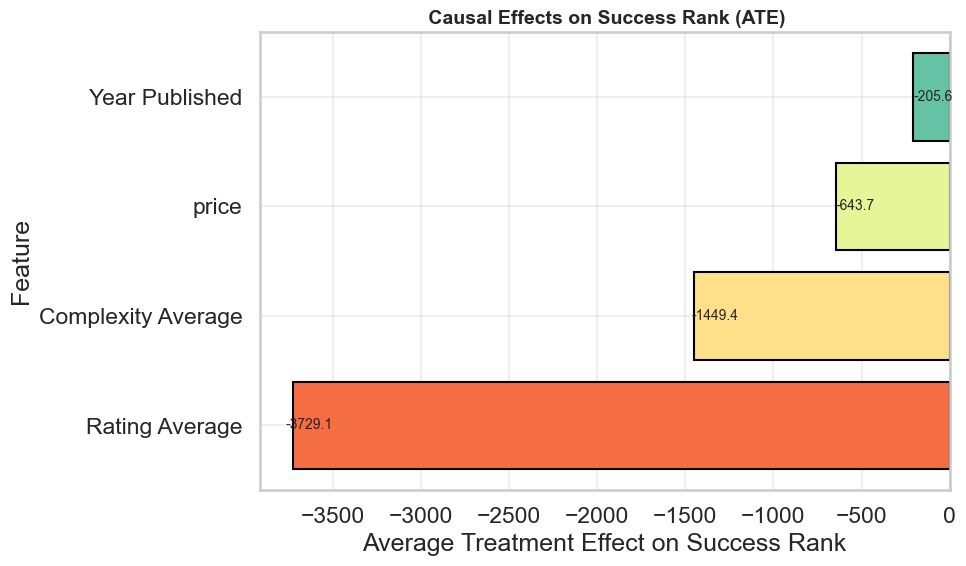

In [20]:
#  Causal Results

causal_results = {
    "Rating Average": -3729.1088,
    "Complexity Average":-1449.4188,
    "price": -643.7472,
    "Year Published": -205.5543,
    
}

df_causal = pd.DataFrame.from_dict(
    causal_results, orient="index", columns=["ATE"]
).sort_values("ATE")


# BAR PLOT

plt.figure(figsize=(10, 6))

colors = sns.color_palette("Spectral", len(df_causal))

bars = plt.barh(
    df_causal.index,
    df_causal["ATE"],
    color=colors,
    edgecolor="black"
)

# Zero line
plt.axvline(0, color="black", linestyle="--", linewidth=1)

# Labels on bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width * 1.01 if width < 0 else width * 1.01,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}",
        va="center",
        fontsize=10
    )

plt.title(" Causal Effects on Success Rank (ATE)", fontsize=14, weight="bold")
plt.xlabel("Average Treatment Effect on Success Rank")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
